# 06. Neural identification and control

Original study laboratory. All generated data are synthetic.

The illustrative nonlinear transition is
$c^+=u+(c-u)\exp[-T_s(1+0.6c)/10]$. It freezes the flushing coefficient
over a sample and is explicitly different from the article benchmarks.
Fit a tanh MLP and a Gaussian RBF network with normalization learned on
training inputs only. Validate untouched transitions, a recursive trajectory
and out-of-domain points separately. The controller evaluates bounded actions
through the trained MLP. Perceptron classification and SOM clustering use the
same input domain to illustrate distinct learning objectives.

## Prepare the environment

Run the next cell once in Colab. Locally, install `requirements.txt` and open this notebook within the repository. The cell only downloads the public repository when running in Colab and no checkout is present.

In [1]:
from pathlib import Path
import sys, subprocess
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB and not Path("python/intelligent_control").exists():
    checkout = Path("/content/intelligent-process-control")
    if not checkout.exists():
        subprocess.run(["git", "clone", "https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation.git", str(checkout)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(checkout / "requirements.txt")], check=True)
    import os
    os.chdir(checkout)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "python/intelligent_control").is_dir())
sys.path.insert(0, str(ROOT / "python"))
print("Environment ready")

Environment ready


## Read the method visually

![Unit 06 conceptual diagram](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/main/course/figures/learning/unit-06.png)

Chronology separates fitting, selection and final scoring. Fit normalization on the training set and freeze it before evaluating the others. A one-step predictor sees measured history; the recursive path sees its own past predictions. Read these scores separately, and use the out-of-domain experiment to expose unsupported extrapolation.

The conceptual diagram is deliberately separate from the computed experiment below. [Editable SVG](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/course/figures/learning/unit-06.svg).

## Run the experiment

Read the model and controller definitions alongside the results. Every rerun writes the metrics, trace CSV files and figure from the current parameters. Unit 7 includes nested optimization and costs more than the other units.

In [2]:
from intelligent_control.experiments import run_unit
import json
result = run_unit(6, ROOT / "laboratories/06-neural-identification-control/results")
print(json.dumps(result["summary"], indent=2))

{
  "models": {
    "MLP": {
      "max_abs_error": 0.0019866280656837265,
      "mean_abs_error": 0.00025138690137498353,
      "sse": 3.458144932920427e-05,
      "mse": 1.3832579731681708e-07,
      "rmse": 0.0003719217623597967,
      "vaf_percent": 99.99974495735108,
      "r_squared": 0.9999974446822414,
      "free_run_rmse": 0.0015491954049571812
    },
    "RBF": {
      "max_abs_error": 0.0011055846794069124,
      "mean_abs_error": 0.00011963490803138005,
      "sse": 7.670523584425632e-06,
      "mse": 3.068209433770253e-08,
      "rmse": 0.00017516305072047165,
      "vaf_percent": 99.99994427558468,
      "r_squared": 0.9999994332040585,
      "free_run_rmse": 0.000432060569459126
    }
  },
  "training_samples": 650,
  "validation_samples": 250,
  "perceptron_accuracy": 1.0,
  "som_quantization_error": 0.11539883513128943,
  "som_occupied_nodes": 9,
  "neural_control": {
    "iae": 1.8853691642485184,
    "ise": 0.47568809509108356,
    "itae": 84.19768379321643,
    "co

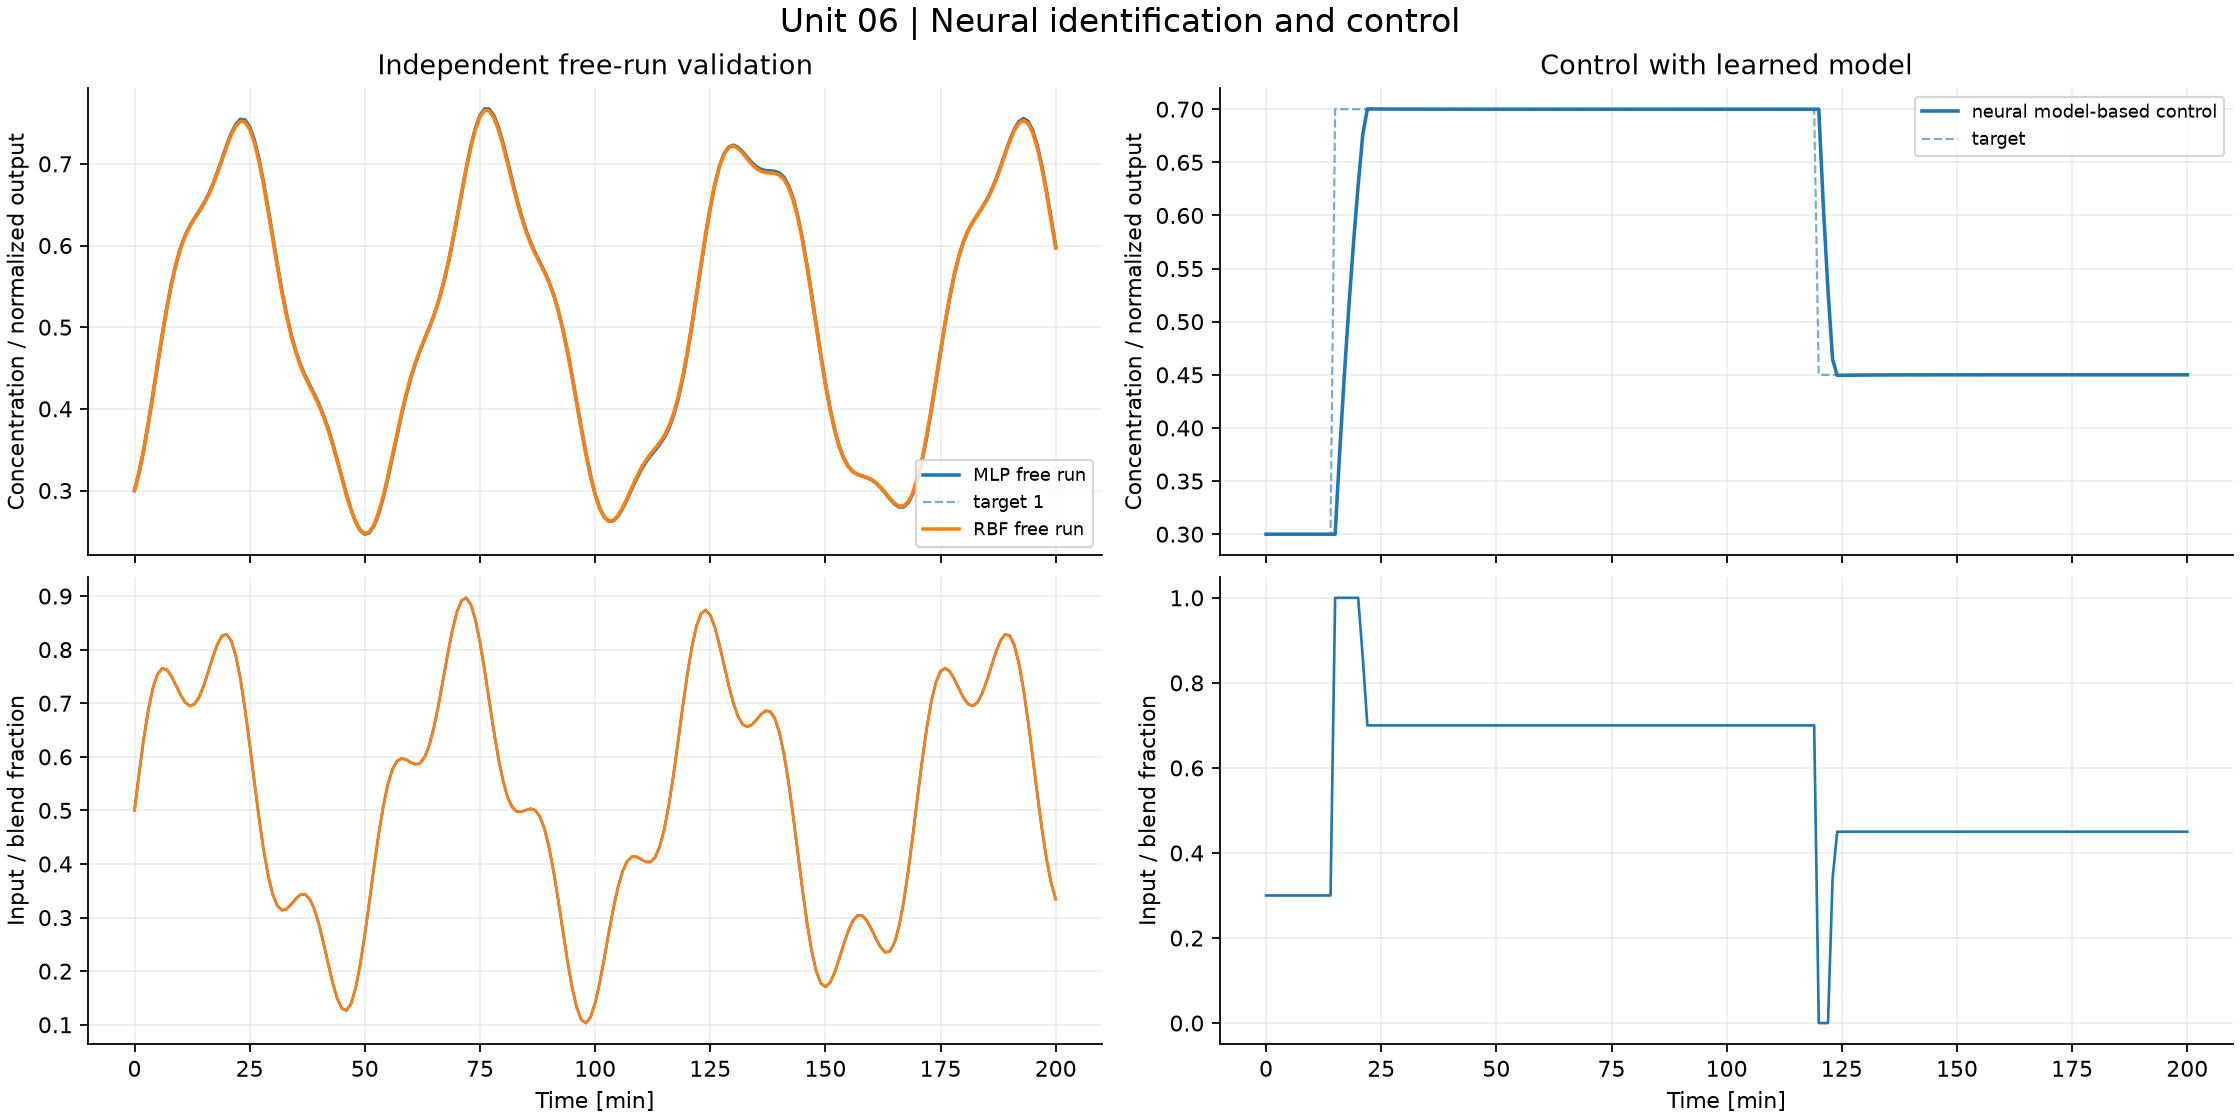

In [3]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "laboratories/06-neural-identification-control/results/comparison.png")))

## Inspect the evidence

1. Identify the physical assumptions, input limits and units.
2. Explain a visible transient using the governing equation.
3. Change one model or controller parameter, rerun and compare the saved metrics.
4. State what the test does and does not establish.

Use the [course guide](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/course/README.md), [worked problems](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/problem-sets/README.md) and [benchmark inventory](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/README.md) for the corresponding derivations and extensions.

## Apply this unit to the article benchmarks

[Worked benchmark study for Unit 06](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/learning/unit-06.md)

![Unit 06 benchmark study](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/main/benchmarks/learning/figures/unit-06.png)

Read the per-model method, chosen signals, numerical results and interpretation in the linked study. The learning track declares its local-model approximations and separates equation-based experiments from external datasets and simulators. It does not turn an unavailable measured record into a synthetic benchmark result.